# 数据下载
平行语料库下载：www.manythings.org/anki/
打开网页后如下图所示
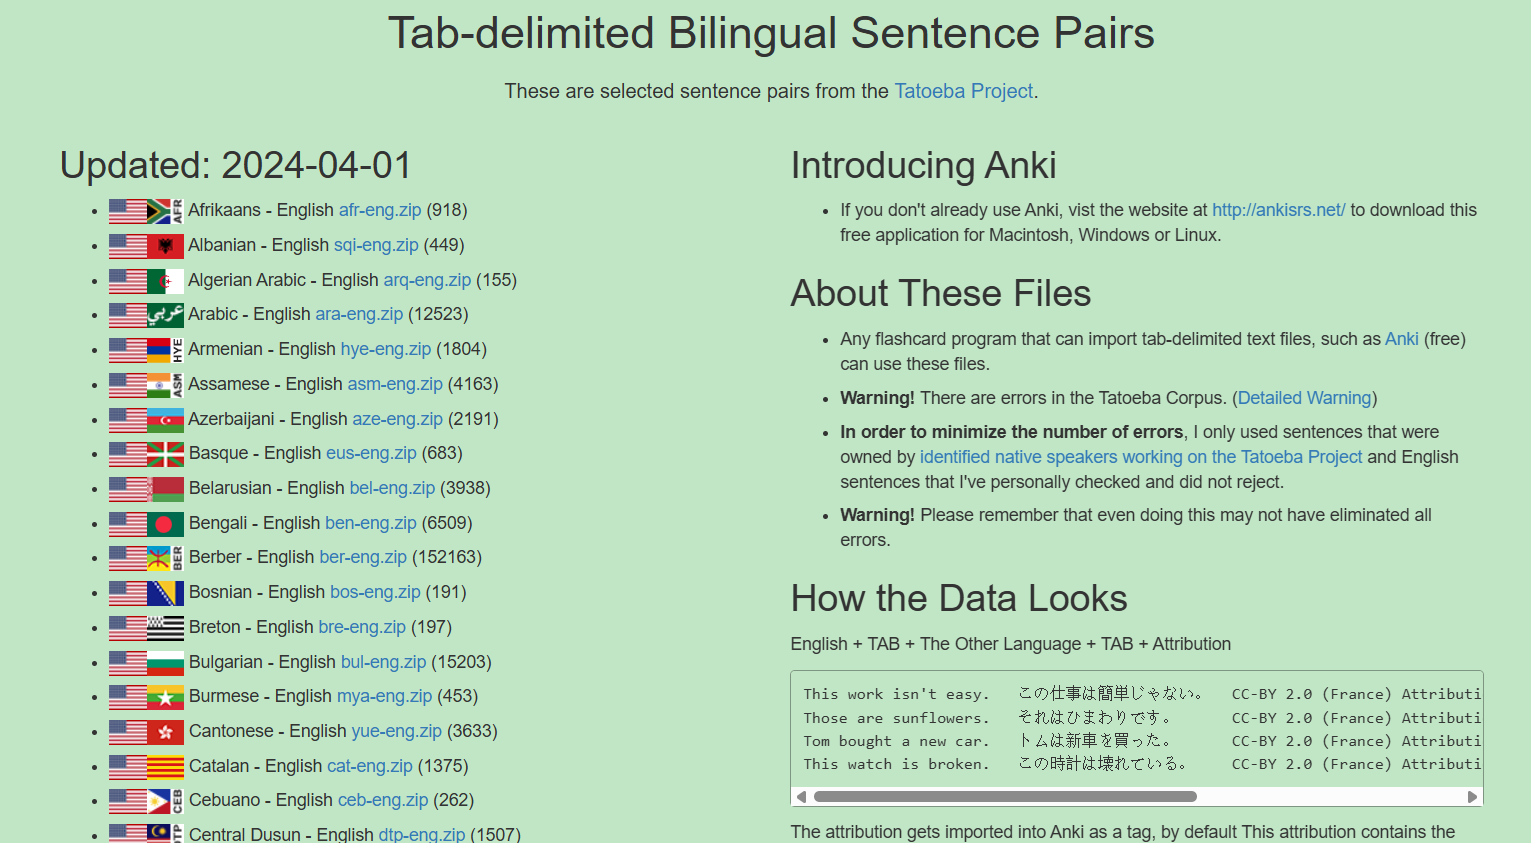


# 模型结构
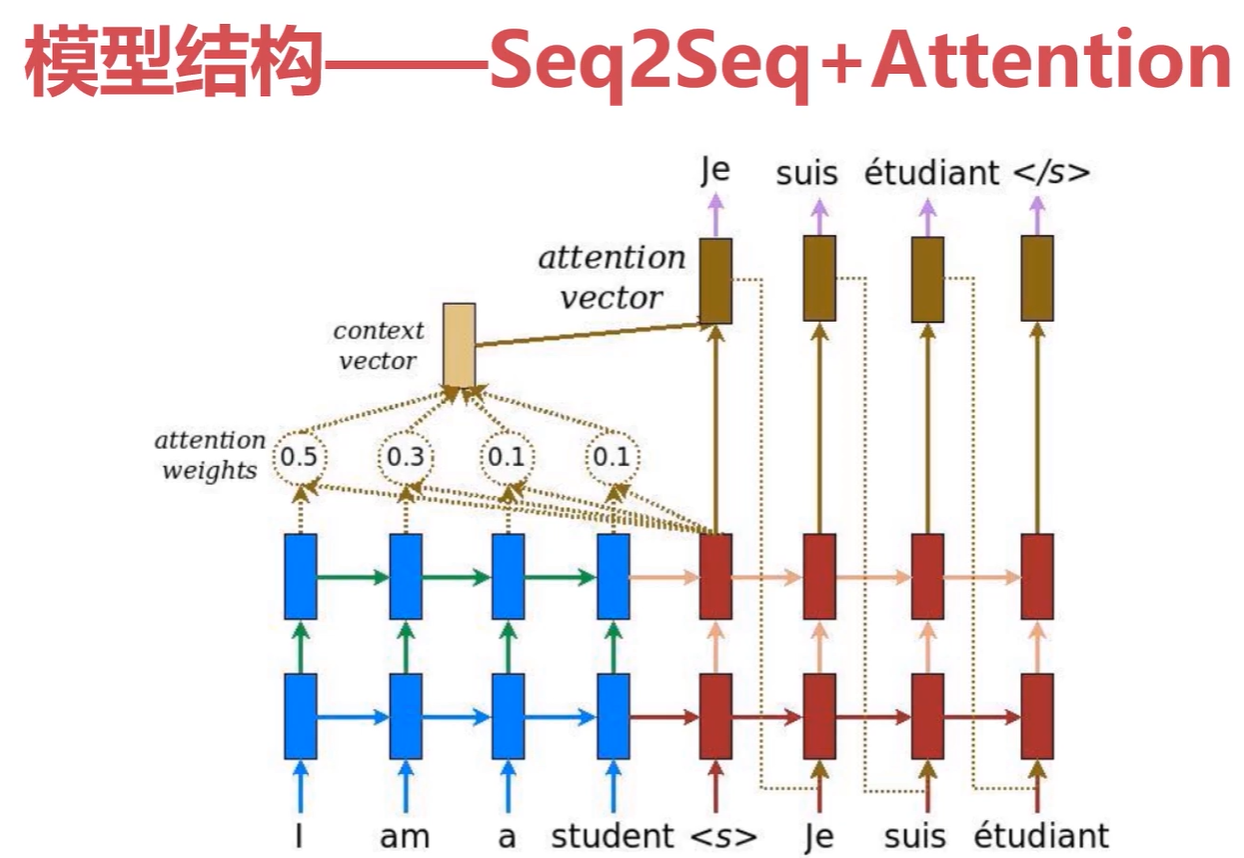

# 1、对语料进行分析统计

In [1]:
import jieba
from utils import normalizeString
from utils import cht_to_chs

In [2]:
SOS_token = 0
EOS_token = 1
MAX_LENGTH1 = 10import jieba
from utils import normalizeString
from utils import cht_to_chs

class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {}
        self.word2count = {}
        self.index2word = {
            0:"SOS", 1:"EOS"
        }
        self.n_words = 2
        
    def addWord(self, word):
        if word not in self.word2index:
            self.word2index[word] = self.n_words
            self.word2count[word] = 1
            self.index2word[self.n_words] = word
            self.n_words += 1
        else:
            self.word2count[word] += 1
            
    def addSentence(self, sentence):
        for word in sentence.split(" "):
            self.addWord(word)
            
def readLangs(lang1, lang2, path):
    lines = open(path, encoding="utf-8").readlines()
    
    lang1_cls = Lang(lang1)
    lang2_cls = Lang(lang2)
    
    pairs = []
    for l in lines:
        l = l.split("\t")
        sentence1 = normalizeString(l[0])
        sentence2 = cht_to_chs(l[1])
        
        seg_list  = jieba.cut(sentence2, cut_all=False)
        sentence2 = " ".join(seg_list)
        
        if len(sentence1.split(" ")) > MAX_LENGTH1:
            continue
        if len(sentence2.split(" ")) > MAX_LENGTH1:
            continue
            
        pairs.append([sentence1,sentence2])
        lang1_cls.addSentence(sentence1)
        lang2_cls.addSentence(sentence2)
        
    return lang1_cls, lang2_cls, pairs

In [3]:
lang1 = "en"
lang2 = "cn"
path = "./cmn-eng/cmn.txt"

lang1_cls, lang2_cls, pairs = readLangs(lang1, lang2, path)

Building prefix dict from the default dictionary ...
Loading model from cache C:\Users\DELL\AppData\Local\Temp\jieba.cache
Loading model cost 0.421 seconds.
Prefix dict has been built successfully.


In [4]:
print(len(pairs))
print(lang1_cls.n_words)
print(lang1_cls.word2index)

26547
6377
{'hi': 2, '.': 3, 'run': 4, 'stop': 5, '!': 6, 'wait': 7, 'begin': 8, 'hello': 9, 'i': 10, 'try': 11, 'won': 12, 'oh': 13, 'no': 14, 'cheers': 15, 'got': 16, 'it': 17, '?': 18, 'he': 19, 'ran': 20, 'hop': 21, 'in': 22, 'know': 23, 'quit': 24, 'm': 25, 'ok': 26, 'up': 27, 'listen': 28, 'way': 29, 'really': 30, 'thanks': 31, 'we': 32, 'why': 33, 'me': 34, 'ask': 35, 'tom': 36, 'awesome': 37, 'be': 38, 'calm': 39, 'fair': 40, 'kind': 41, 'nice': 42, 'call': 43, 'us': 44, 'come': 45, 'get': 46, 'out': 47, 'go': 48, 'away': 49, 'home': 50, 'goodbye': 51, 'hang': 52, 'on': 53, 'came': 54, 'runs': 55, 'help': 56, 'hit': 57, 'hold': 58, 'hug': 59, 'agree': 60, 'hot': 61, 'ill': 62, 'sad': 63, 'shy': 64, 'wet': 65, 's': 66, 'join': 67, 'keep': 68, 'kiss': 69, 'perfect': 70, 'see': 71, 'you': 72, 'shut': 73, 'skip': 74, 'take': 75, 'tell': 76, 'wake': 77, 'wash': 78, 'welcome': 79, 'who': 80, 'not': 81, 'win': 82, 'back': 83, 'off': 84, 'still': 85, 'beats': 86, 'cuff': 87, 'him': 88,

In [5]:
print(lang2_cls.n_words)
print(lang2_cls.index2word)

11153
{0: 'SOS', 1: 'EOS', 2: '嗨', 3: '。', 4: '你好', 5: '你', 6: '用', 7: '跑', 8: '的', 9: '住手', 10: '！', 11: '等等', 12: '等', 13: '一下', 14: '开始', 15: '我', 16: '试试', 17: '赢', 18: '了', 19: '不会', 20: '吧', 21: '干杯', 22: '!', 23: '知道', 24: '没有', 25: '？', 26: '懂', 27: '吗', 28: '他', 29: '跳进来', 30: '退出', 31: '不', 32: '干', 33: '没事', 34: '已经', 35: '起来', 36: '听', 37: '着', 38: '可能', 39: '没门', 40: '真的', 41: '确定', 42: '谢谢', 43: '我们', 44: '来', 45: '为什么', 46: '是', 47: '去', 48: '问', 49: '汤姆', 50: '好棒', 51: '冷静', 52: '点', 53: '公平', 54: '友善', 55: '友好', 56: '和', 57: '气点', 58: '联系', 59: '进来', 60: '找到', 61: '滚出去', 62: '出去', 63: '走开', 64: '滚', 65: '回家', 66: '回家吧', 67: '再见', 68: '告辞', 69: '坚持', 70: '他来', 71: '帮', 72: '帮帮', 73: '打', 74: '抱抱', 75: '请', 76: '抱紧', 77: '同意', 78: '觉得', 79: '很', 80: '热', 81: '生病', 82: '难过', 83: '害羞', 84: '湿', 85: '没关系', 86: '加入', 87: '留着', 88: '吻', 89: '完美', 90: '闭嘴', 91: '不管', 92: '它', 93: '拿走', 94: '告诉', 95: '胜利', 96: '醒醒', 97: '清洗', 98: '欢迎', 99: '谁', 100: '算你狠', 101: '往', 102: '后退', 

# 2、seq2seq+attention编码器实现（encoder）

# 2.1前置知识介绍——nn.GRU
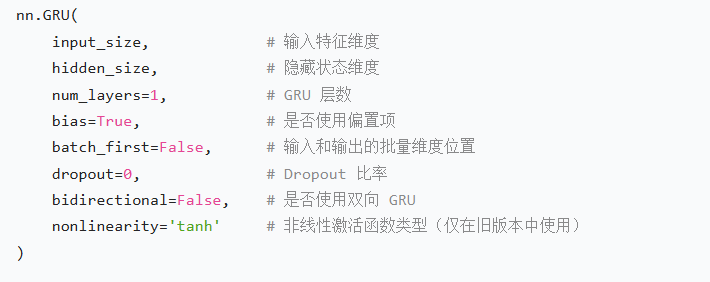
参数详解
1. input_size
含义：输入数据的特征维度。
示例：在自然语言处理中，若使用 300 维的词向量，则 input_size=300。
类型：整数。
2. hidden_size
含义：隐藏状态的维度，即每个 GRU 单元输出的向量维度。
作用：决定了模型的表示能力，值越大，模型能学习的模式越复杂。
类型：整数。
3. num_layers
含义：堆叠的 GRU 层数。
示例：num_layers=2 表示两层 GRU 堆叠，第二层接收第一层的输出作为输入。
注意：层数越多，模型表达能力越强，但计算开销和过拟合风险也会增加。
类型：整数，默认值为 1。
4. bias
含义：是否在 GRU 单元中使用偏置项（即线性变换中的 
b
）。
类型：布尔值，默认值为 True。
5. batch_first
含义：控制输入和输出张量的维度顺序。
若为 False（默认），输入形状为 (seq_len, batch, input_size)。
若为 True，输入形状为 (batch, seq_len, input_size)。
建议：在处理批量数据时，推荐使用 batch_first=True，因为它更符合 PyTorch 其他模块（如 nn.Linear）的输入习惯。
类型：布尔值，默认值为 False。
6. dropout
含义：在每层 GRU 的输出上应用 Dropout 的比率（丢弃神经元的概率）。
作用：防止过拟合，通常在训练时使用。
注意：仅当 num_layers > 1 时有效，因为 Dropout 只应用于层与层之间。
类型：浮点数，范围为 [0, 1]，默认值为 0。
7. bidirectional
含义：是否使用双向 GRU。
单向 GRU 只考虑序列的前向信息。
双向 GRU 同时考虑前向和后向信息，输出维度会翻倍（hidden_size * 2）。
适用场景：在自然语言处理中，双向 GRU 能更好地捕捉上下文信息（如文本分类、机器翻译）。
类型：布尔值，默认值为 False。
8. nonlinearity
含义：旧版本中的参数，指定激活函数类型（'tanh' 或 'relu'）。
注意：在 PyTorch 1.0 及以后版本中，此参数已被弃用，GRU 固定使用 tanh 作为激活函数。
类型：字符串，默认值为 'tanh'。

# 2.2 nn.GRU实例的返回值介绍
## 2.2.1 GRU的返回值形状
| 返回值 | 形状 | 内容 |
| ---- | ---- | ---- |
| output | (batch, seq_len, hidden_size*num_directions) | 每个时间步的隐藏状态，可用于捕获序列中的时序特征（如文本中的上下文信息）。在双向GRU中，该维度因前向和后向隐藏状态拼接而使hidden_size翻倍  |
| h_n | (num_layers*num_directions, batch, hidden_size) | 仅包含最后一个时间步的隐藏状态（对多层GRU，每层都有一个状态；双向GRU中，包含前向和后向最后时间步状态）  | 
## 2.2.2 GRU数据流动分析
**一、GRU 的层间传递机制**
对于多层 GRU（例如 2 层），数据流动如下：

1. **第一层**接收输入序列 `x`，并输出每个时间步的隐藏状态：
   $h_1^{(1)}, h_2^{(1)}, ..., h_t^{(1)}$
2. **第二层**接收第一层的输出作为输入，并生成自己的隐藏状态：
   $h_1^{(2)}, h_2^{(2)}, ..., h_t^{(2)}$
3. 以此类推，直到最后一层。

**`output` 只包含最后一层的隐藏状态**（即 $h_1^{(L)}, h_2^{(L)}, ..., h_t^{(L)}$ ），因此与层数无关。 


**二、多层 GRU 的数据流动**  
对于一个 `num_layers=3` 的 GRU，数据在层间的传递方式如下：

1. **第一层**处理输入序列 `x`，输出 $h₁^{(1)}, h₂^{(1)}, ..., hₜ^{(1)}$。  
   - 最后一个时间步的状态为 $hₜ^{(1)}$。

2. **第二层**接收第一层的输出作为输入，输出 $h₁^{(2)}, h₂^{(2)}, ..., hₜ^{(2)}$。  
   - 最后一个时间步的状态为 $hₜ^{(2)}$。

3. **第三层**同理，最后一个时间步的状态为 $hₜ^{(3)}$。

**`h_n` 需要保存所有层的最后状态**，即 $[hₜ^{(1)}, hₜ^{(2)}, hₜ^{(3)}]$。

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [6]:
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(EncoderRNN, self).__init__()
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(input_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size)
        
    def forward(self, input, hidden):
        embedded = self.embedding(input).view(1, 1, -1)
        output = embedded
        output, hidden = self.gru(output, hidden)
        
        return output, hidden
    
    def initHidden(self):
        return torch.zeros(1, 1, self.hidden_size, device=device)
        

In [24]:
device

device(type='cpu')

# 3、seq2seq_attention 译码器实现（decoder）

# 知识拓展
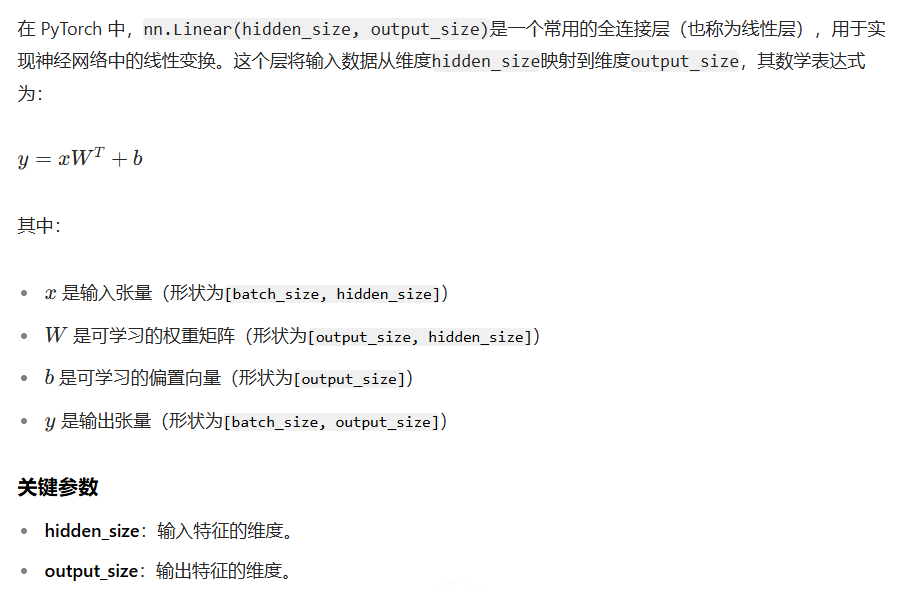

In [8]:
class DecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size):
        super(DecoderRNN, self).__init__()
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.gru = nn.GRU(hidden_size, hidden_size)
        self.out = nn.Linear(hidden_size, output_size)
        self.softmax = nn.LogSoftmax(dim=1)
        
    def forward(self, input, hidden):
        output = self.embedding(input).view(1, 1 , -1)
        output = F.relu(output)                     
        output, hidden = self.gru(output, hidden)   #调用输出的全连接层
        output = self.softmax(self.out(output[0]))  #全连接层 self.out 的输入需要是二维张量 [batch_size, hidden_size]。如果不使用 output[0]，直接传入三维张量 [1, 1, hidden_size] 会导致维度不匹配错误。
        return output, hidden

    def initHidden(self):
        return torch.zeros(1, 1, self.hidden_size, device=device)

In [7]:
class AttenDecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, dropout_p=0.1, max_len=MAX_LENGTH1):
        super(AttenDecoderRNN, self).__init__()
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.dropout_p = dropout_p
        self.max_len = max_len

        self.embedding = nn.Embedding(self.output_size, self.hidden_size)
        self.attn = nn.Linear(self.hidden_size * 2, self.max_len)
        self.attn_combine = nn.Linear(self.hidden_size * 2, self.hidden_size)

        self.dropout = nn.Dropout(self.dropout_p)

        self.gru = nn.GRU(self.hidden_size, self.hidden_size)
        self.out = nn.Linear(self.hidden_size, self.output_size)

    def forward(self, input, hidden, encoder_outputs):
        embedded = self.embedding(input).view(1, 1, -1)
        embedded = self.dropout(embedded)

        atten_weight = F.softmax(
            self.attn(torch.cat([embedded[0], hidden[0]], 1)),
            dim=1
        )

        att_applied = torch.bmm(
            atten_weight.unsqueeze(0),    #维度从(seq_len=1,MAX_LEN)变为(batch_size=1,seq_len=1,MAX_LEN)
            encoder_outputs.unsqueeze(0)  #维度从(MAX_LEN,hidden_size)变为(batch_size=1,MAX_LEN,hidden_size)
        )                                 #经过torch.bmm乘法，att_applied的维度为(batch_size=1,seq_len=1,hidden_size)
        output = torch.cat([embedded[0], att_applied[0]], dim=1)
        output = self.attn_combine(output).unsqueeze(0)
        output = F.relu(output)
        output, hidden = self.gru(output, hidden)
        output = F.log_softmax(self.out(output[0]), dim=1)

        return output, hidden, atten_weight

    def initHidden(self):
        return torch.zeros(1, 1, self.hidden_size, device=device)

# 4、 模型训练及保存

In [ ]:
import random
from torch import optim
from utils import timeSince
import time

MAX_LENGTH = 11

lang1 = "en"
lang2 = "cn"
path = "./cmn-eng/cmn.txt"
input_lang, output_lang, pairs = readLangs(lang1, lang2, path)
#print(len(pairs))
#print(input_lang.n_words)
#print(input_lang.index2word)

#print(output_lang.n_words)
#print(output_lang.index2word)

def listTotensor(input_lang, data):
    indexes_in = [input_lang.word2index[word] for word in data.split(" ")]
    indexes_in.append(EOS_token)
    input_tensor = torch.tensor(indexes_in,
                                dtype=torch.long,
                                device=device).view(-1, 1)
    return input_tensor


def tensorsFromPair(pair):
    input_tensor = listTotensor(input_lang, pair[0])
    output_tensor = listTotensor(output_lang, pair[1])
    return (input_tensor, output_tensor)


def loss_func(input_tensor,
                     output_tensor,
                     encoder,
                     decoder,
                     encoder_optimizer,
                     decoder_optimizer,
                  scheduler_encoder,
                  scheduler_decoder,
                     criterion):
    encoder_hidden = encoder.initHidden()

    encoder_optimizer.zero_grad()  #（1）清空梯度缓存：将所有参数的梯度（param.grad）设置为零张量。（2）止梯度错误累积：确保每次迭代的梯度计算独立，避免影响后续更新
    decoder_optimizer.zero_grad()

    input_len = input_tensor.size(0)
    output_len = output_tensor.size(0)

    encoder_outputs = torch.zeros(MAX_LENGTH, encoder.hidden_size, device=device)

    for ei in range(input_len):
        encoder_output, encoder_hidden = encoder(input_tensor[ei], encoder_hidden)
        encoder_outputs[ei] = encoder_output[0, 0]

    decoder_hidden = encoder_hidden
    decoder_input = torch.tensor([[SOS_token]], device=device)
    use_teacher_forcing = True if random.random() < 0.5 else False

    loss = 0
    if use_teacher_forcing:
        for di in range(output_len):
            decoder_output, decoder_hidden, decoder_attention = decoder(
                decoder_input, decoder_hidden, encoder_outputs
            )

            loss += criterion(decoder_output, output_tensor[di])
            decoder_input = output_tensor[di]
    else:
        for di in range(output_len):
            decoder_output, decoder_hidden, decoder_attention = decoder(
                decoder_input, decoder_hidden, encoder_outputs
            )
            loss += criterion(decoder_output, output_tensor[di])

            topV, topi = decoder_output.topk(1)
            decoder_input = topi.squeeze().detach()

            if decoder_input.item() == EOS_token:
                break

    loss.backward()           #后向传播
    encoder_optimizer.step()  #参数更新
    decoder_optimizer.step()  #参数更新
    return loss.item() / output_len




hidden_size = 256
encoder = EncoderRNN(input_lang.n_words, hidden_size).to(device)
decoder = AttenDecoderRNN(hidden_size,
                          output_lang.n_words,
                          max_len = MAX_LENGTH,
                          dropout_p = 0.1).to(device)

lr = 0.01
encoder_optimizer = optim.SGD(encoder.parameters(), lr=lr)
decoder_optimizer = optim.SGD(decoder.parameters(), lr=lr)

scheduler_encoder = torch.optim.lr_scheduler.StepLR(encoder_optimizer,
                                                    step_size=1,
                                                    gamma=0.95)
scheduler_decoder = torch.optim.lr_scheduler.StepLR(decoder_optimizer,
                                                    step_size=1,
                                                    gamma=0.95)

criterion = nn.NLLLoss()

n_iters = 1000000
training_pairs = [
    tensorsFromPair(random.choice(pairs)) for i in range(n_iters)
]

print_every = 100
save_every = 1000

print_loss_total = 0
start = time.time()

for iter in range(1, n_iters + 1):
    training_pair = training_pairs[iter - 1]
    input_tensor = training_pair[0]
    output_tensor = training_pair[1]

    loss = loss_func(input_tensor,
                     output_tensor,
                     encoder,
                     decoder,
                     encoder_optimizer,
                     decoder_optimizer,
                     scheduler_encoder,
                     scheduler_decoder,
                     criterion)
    print_loss_total += loss

    if iter % print_every == 0:
        print_loss_avg = print_loss_total / print_every
        print_loss_total = 0
        print("{},{},{},{}".format(timeSince(start, iter/n_iters),
                                   iter, iter / n_iters * 100,
                                   print_loss_avg))

    if iter % save_every == 0:
        torch.save(encoder.state_dict(),
                   "models/encoder_{}.pth".format(iter))
        torch.save(decoder.state_dict(),
                   "models/decoder_{}.pth".format(iter))

    if iter % 10000 == 0:
        scheduler_encoder.step()
        scheduler_decoder.step()

0m 3s (- 617m 10s),100,0.01,5.7777342978390775
0m 7s (- 650m 50s),200,0.02,5.422668569601976
0m 11s (- 648m 9s),300,0.03,5.147947021180246
0m 15s (- 640m 57s),400,0.04,5.224289653422341
0m 18s (- 628m 30s),500,0.05,4.842100663563562
0m 22s (- 630m 32s),600,0.06,4.80824674401345
0m 26s (- 623m 25s),700,0.06999999999999999,5.017263918938575
0m 29s (- 614m 48s),800,0.08,5.039446091205357
0m 32s (- 609m 42s),900,0.09,4.8651128778340675
0m 36s (- 610m 18s),1000,0.1,4.779070904073948
0m 40s (- 609m 50s),1100,0.11,4.845170179629908
0m 43s (- 607m 9s),1200,0.12,4.828391944058184
0m 47s (- 606m 12s),1300,0.13,4.7398905676137115
0m 51s (- 610m 24s),1400,0.13999999999999999,4.797455273504382
0m 55s (- 616m 9s),1500,0.15,4.747049887770009
0m 59s (- 621m 15s),1600,0.16,4.667411318412246
1m 3s (- 623m 41s),1700,0.16999999999999998,5.05192492022315
1m 7s (- 624m 54s),1800,0.18,4.654034721943551
1m 11s (- 625m 1s),1900,0.19,4.613168927505762
1m 15s (- 626m 23s),2000,0.2,4.888022620192853
1m 19s (- 626

# 5、模型加载

In [1]:
import random
from torch import optim
from utils import timeSince
import time

MAX_LENGTH = 11

lang1 = "en"
lang2 = "cn"
path ="C:\Users\Lenovo\Downloads\cmn-eng\cmn.txt"
input_lang, output_lang, pairs = readLangs(lang1, lang2, path)
#print(len(pairs))
#print(input_lang.n_words)
#print(input_lang.index2word)

#print(output_lang.n_words)
#print(output_lang.index2word)

def listTotensor(input_lang, data):
    indexes_in = [input_lang.word2index[word] for word in data.split(" ")]
    indexes_in.append(EOS_token)
    input_tensor = torch.tensor(indexes_in,
                                dtype=torch.long,
                                device=device).view(-1, 1)
    return input_tensor


def tensorsFromPair(pair):
    input_tensor = listTotensor(input_lang, pair[0])
    output_tensor = listTotensor(output_lang, pair[1])
    return (input_tensor, output_tensor)



hidden_size = 256
encoder = EncoderRNN(input_lang.n_words, hidden_size).to(device)
decoder = AttenDecoderRNN(hidden_size,
                          output_lang.n_words,
                          max_len = MAX_LENGTH,
                          dropout_p = 0.1).to(device)

encoder.load_state_dict(torch.load("C:\Users\Lenovo\models\encoder_10000.pth"))
decoder.load_state_dict(torch.load("./models_rlt/decoder_1000000.pth"))


SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 2-3: truncated \UXXXXXXXX escape (3660486361.py, line 10)

In [16]:
n_iters = 1

#train_sen_pairs = [
#    random.choice(pairs) for i in range(n_iters)
#]
train_sen_pairs = [['this class is interesting .', '今天 天气  好 。']]
training_pairs = [
    tensorsFromPair(train_sen_pairs[i]) for i in range(n_iters)
]


In [17]:
n_iters = 1

#train_sen_pairs = [
#    random.choice(pairs) for i in range(n_iters)
#]
train_sen_pairs = [['this class is interesting .', '今天 天气  好 。']]
training_pairs = [
    tensorsFromPair(train_sen_pairs[i]) for i in range(n_iters)
]
for i in range(n_iters):
    input_tensor, output_tensor = training_pairs[i]
    encoder_hidden = encoder.initHidden()
    input_len = input_tensor.size(0)
    encoder_outputs = torch.zeros(MAX_LENGTH, encoder.hidden_size, device = device)
    for ei in range(input_len):
        encoder_output, encoder_hidden = encoder(input_tensor[ei], encoder_hidden)
        encoder_outputs[ei] = encoder_output[0, 0]
        
    decoder_hidden = encoder_hidden
    decoder_input = torch.tensor([[SOS_token]], device=device)
    
    decoder_words = []
    for di in range(MAX_LENGTH):
        decoder_output, decoder_hidden, decoder_attention = decoder(
            decoder_input, decoder_hidden, encoder_outputs
        )
        
        topV, topi = decoder_output.topk(1)
        decoder_input = topi.squeeze().detach()
        
        if topi.item() == EOS_token:
            decoder_words.append("<EOS>")
            break
        else:
            decoder_words.append(output_lang.index2word[topi.item()])
            
            
    print(train_sen_pairs[i][0])
    #print(train_sen_pairs[i][1])
    print(decoder_words)

this class is interesting .
['这个', '奇怪', '很', '有意思', '。', '<EOS>']
